# 02 · Análisis estadístico: qué se asocia con el precio y qué papel tiene la renta de la zona

## Introducción

El notebook 01 describió el conjunto unido de Inside Airbnb (nueve ciudades y regiones de España) y del Atlas de
Distribución de Renta de los Hogares del INE. Aquí se contrastan formalmente las preguntas que salieron de esa
exploración:

1. ¿Difiere el precio entre ciudades y entre tipos de habitación, y cuánto?
2. ¿Se relaciona la renta de la zona con el precio, en conjunto y dentro de cada ciudad?
3. Controlando a la vez por el alojamiento, la ciudad, el anfitrión y la fecha de la cotización, ¿qué asociación
   queda entre la renta y el precio, y cuánto añade a la explicación del precio?
4. ¿Mejora un modelo de machine learning a la regresión lineal, validado de forma honesta?

**Reglas de juego.** Cada contraste declara su hipótesis nula (H0) y alternativa (H1) antes de ejecutarse, usa
α = 0,05, comprueba sus supuestos e informa del tamaño del efecto. Con decenas de miles de anuncios casi cualquier
diferencia es «significativa», así que lo que se interpreta es la magnitud. Los anuncios de un mismo anfitrión no
son independientes, y los de un mismo distrito comparten la misma renta: se usan errores agrupados, bootstrap por
clusters y sensibilidades. Cuando hay muchas pruebas a la vez se corrige la multiplicidad (Bonferroni o Holm).
Nada de lo que sigue es causal: son asociaciones observadas.

Las cifras del texto se leen de `reports/findings.json` o se calculan en la celda; ninguna está escrita a mano.
El notebook se genera desde `notebooks/fuentes_py/02_analisis_estadistico.py`.

In [1]:
import sys
from pathlib import Path

sys.dont_write_bytecode = True
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import json
import logging

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy import stats

from src import config, estadistica as est, formato as fmt, visualizacion as viz
from src.analisis import NOMBRE_CIUDAD

logging.disable(logging.WARNING)
%matplotlib inline
viz.configurar_estilo()
plt.rcParams["figure.dpi"] = 60
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

df = pd.read_parquet(config.RUTA_PARQUET)
cp = df[df["precio_valido"]].assign(nombre_ciudad=lambda d: d["ciudad"].map(NOMBRE_CIUDAD))
with open(config.RUTA_FINDINGS, encoding="utf-8") as f:
    findings = json.load(f)
E, D = findings["estadistica"], findings["descriptivo"]
RP, OLS, ML = E["renta_precio"], E["ols"], E["ml"]


def lectura(texto: str) -> None:
    """Muestra una interpretación en Markdown (las cifras van dentro del f-string, nunca a mano)."""
    display(Markdown(texto))


print(f"Anuncios con precio: {fmt.n0(len(cp))} de {fmt.n0(len(df))}")

Anuncios con precio: 89.614 de 109.437


## 1. Normalidad y elección de contrastes

H0: el precio sigue una distribución normal. H1: no la sigue. Se usa D'Agostino-K² sobre todos los datos y
Shapiro-Wilk sobre una muestra (Shapiro no admite muestras tan grandes). El gráfico Q-Q del logaritmo ayuda a ver
cuánto se aleja de la normal.

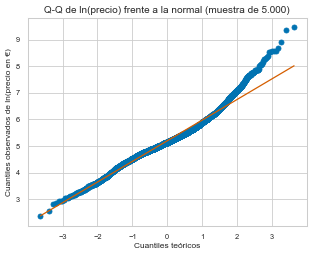

In [2]:
k2, p_k2 = stats.normaltest(cp["price"])
k2_log, p_k2_log = stats.normaltest(cp["log_precio"])
fig, ax = plt.subplots(figsize=(6, 4.5))
stats.probplot(cp["log_precio"].sample(5000, random_state=config.SEMILLA), dist="norm", plot=ax)
ax.set(title="Q-Q de ln(precio) frente a la normal (muestra de 5.000)", xlabel="Cuantiles teóricos",
       ylabel="Cuantiles observados de ln(precio en €)")
plt.show()

In [3]:
lectura(f"**Lectura.** D'Agostino-K² rechaza la normalidad del precio (K² = {fmt.n0(k2)}, {fmt.p_texto(p_k2)}) y "
        f"también la de su logaritmo (K² = {fmt.n0(k2_log)}, {fmt.p_texto(p_k2_log)}). El Q-Q muestra que ln(precio) "
        "es casi recto en el centro pero con colas más pesadas que la normal. Por eso se comparan grupos con "
        "Kruskal-Wallis y Mann-Whitney, que trabajan con rangos, y la regresión se ajusta sobre ln(precio) con "
        "errores robustos.")

**Lectura.** D'Agostino-K² rechaza la normalidad del precio (K² = 337.455, p < 0,001) y también la de su logaritmo (K² = 8.321, p < 0,001). El Q-Q muestra que ln(precio) es casi recto en el centro pero con colas más pesadas que la normal. Por eso se comparan grupos con Kruskal-Wallis y Mann-Whitney, que trabajan con rangos, y la regresión se ajusta sobre ln(precio) con errores robustos.

## 2. Diferencias de precio entre ciudades

- H0: la distribución del precio es la misma en las nueve ciudades y regiones.
- H1: al menos una difiere.
- Contraste: Kruskal-Wallis, con ε² como tamaño del efecto (0,01 pequeño, 0,06 mediano, 0,14 grande).
- Si se rechaza H0, post-hoc de Dunn con corrección de Bonferroni para saber qué pares difieren.

In [4]:
grupos = [g["price"].to_numpy() for _, g in cp.groupby("nombre_ciudad")]
h, p_h = stats.kruskal(*grupos)
eps2 = est.epsilon_cuadrado(h, len(cp))
print(f"Kruskal-Wallis por ciudad: H = {fmt.n1(h)}, {fmt.p_texto(p_h)}, ε² = {fmt.n3(eps2)}")
print(f"Pipeline (findings.json): H = {fmt.n1(E['kruskal_ciudad']['estadistico'])}, "
      f"ε² = {fmt.n3(E['kruskal_ciudad']['tamano_efecto']['valor'])}")

Kruskal-Wallis por ciudad: H = 10.228,7, p < 0,001, ε² = 0,114
Pipeline (findings.json): H = 10.228,7, ε² = 0,114


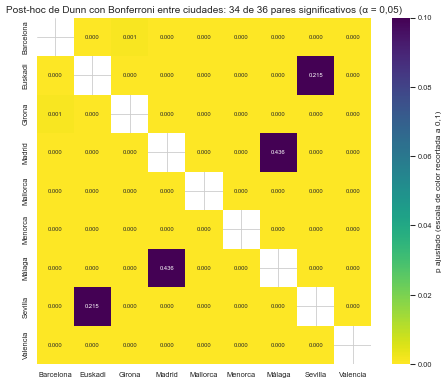

In [5]:
viz.fig_posthoc_ciudades(findings);

In [6]:
ph = E["posthoc_ciudad"]
no_signif = [f"{p['grupo_a']}–{p['grupo_b']}" for p in ph["pares"] if not p["significativo"]]
lectura(f"**Lectura.** Se rechaza H0: el precio difiere entre ciudades, con un efecto "
        f"{E['kruskal_ciudad']['tamano_efecto']['interpretacion']} (ε² = {fmt.n3(eps2)}; el cálculo de la celda "
        "coincide con el del pipeline). El post-hoc de Dunn con Bonferroni encuentra diferencias en "
        f"{ph['n_pares_significativos']} de {ph['n_pares']} pares; no se distinguen: {', '.join(no_signif) or 'ninguno'}. "
        "Es decir, casi todas las ciudades tienen niveles de precio distintos, aunque la ciudad por sí sola explique "
        "una parte moderada de la variación.")

**Lectura.** Se rechaza H0: el precio difiere entre ciudades, con un efecto mediano (ε² = 0,114; el cálculo de la celda coincide con el del pipeline). El post-hoc de Dunn con Bonferroni encuentra diferencias en 34 de 36 pares; no se distinguen: Euskadi–Sevilla, Madrid–Málaga. Es decir, casi todas las ciudades tienen niveles de precio distintos, aunque la ciudad por sí sola explique una parte moderada de la variación.

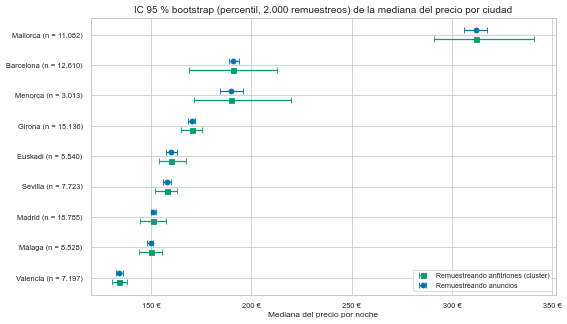

In [7]:
viz.fig_ic_bootstrap(findings);

In [8]:
b = E["bootstrap"]["ciudades"]
lectura(f"**Lectura.** Los intervalos bootstrap de la mediana se calculan de dos formas: remuestreando anuncios y "
        f"remuestreando anfitriones con todos sus anuncios ({fmt.n0(E['bootstrap']['n_boot'])} réplicas). El segundo "
        "respeta que los anuncios de un mismo anfitrión se parecen y da intervalos más anchos, más honestos. "
        f"{b[0]['grupo']} tiene la mediana más alta ({fmt.eur2(b[0]['mediana'])}, IC por anfitrión "
        f"{fmt.eur2(b[0]['ic_inf_cluster'])} – {fmt.eur2(b[0]['ic_sup_cluster'])}), "
        f"{'claramente separada' if E['bootstrap']['top_ciudad_distinguible'] else 'sin separarse claramente'} de la "
        f"segunda, {b[1]['grupo']}.")

**Lectura.** Los intervalos bootstrap de la mediana se calculan de dos formas: remuestreando anuncios y remuestreando anfitriones con todos sus anuncios (2.000 réplicas). El segundo respeta que los anuncios de un mismo anfitrión se parecen y da intervalos más anchos, más honestos. Mallorca tiene la mediana más alta (311,75 €, IC por anfitrión 291,00 € – 341,02 €), claramente separada de la segunda, Barcelona.

## 3. Tipo de habitación, superhost y asociaciones entre categorías

- Tipo de habitación: Kruskal-Wallis (H0: igual distribución del precio en todos los tipos).
- Superhost: Mann-Whitney (H0: P(precio superhost > precio no superhost) = 0,5), con la correlación rank-biserial.
- Chi-cuadrado de independencia (H0: las dos variables son independientes) con la V de Cramér.

In [9]:
filas = []
for clave in ("kruskal_tipo", "mann_whitney_superhost", "chi2_ciudad_tipo", "chi2_tipo_superhost", "chi2_multi_tipo"):
    r = E[clave]
    filas.append({"contraste": r["nombre"], "estadístico": round(r["estadistico"], 1), "p": fmt.pvalor(r["p_valor"]),
                  "efecto": r["tamano_efecto"]["nombre"], "valor": round(r["tamano_efecto"]["valor"], 4),
                  "magnitud": r["tamano_efecto"]["interpretacion"]})
pd.DataFrame(filas)

,contraste,estadístico,p,efecto,valor,magnitud
0,Kruskal-Wallis: precio por tipos de habitación,14448.8,"< 0,001",épsilon cuadrado,0.1612,grande
1,Mann-Whitney U: superhosts vs no superhosts,869232988.5,"< 0,001",correlación rank-biserial,0.0202,despreciable
2,Chi-cuadrado: ciudad y tipo de habitación,8928.9,"< 0,001",V de Cramér,0.1649,pequeño
3,Chi-cuadrado: tipo de habitación y ser superhost,553.1,"< 0,001",V de Cramér,0.0711,despreciable
4,Chi-cuadrado: ser multi-anuncio y tipo de habi...,173.5,"< 0,001",V de Cramér,0.0398,despreciable


In [10]:
mw = E["mann_whitney_superhost"]
uno = E["sensibilidad_un_anuncio_por_host"]
lectura(f"**Lectura.** El tipo de habitación separa mucho los precios (ε² = "
        f"{fmt.n3(E['kruskal_tipo']['tamano_efecto']['valor'])}, efecto {E['kruskal_tipo']['tamano_efecto']['interpretacion']}), "
        "más que la ciudad. La diferencia entre superhosts y el resto es estadísticamente significativa pero "
        f"despreciable (r = {fmt.n4(mw['tamano_efecto']['valor'])}; medianas {fmt.eur2(mw['extra']['mediana_a'])} y "
        f"{fmt.eur2(mw['extra']['mediana_b'])}). Con un anuncio por anfitrión elegido al azar esa diferencia "
        f"{'se mantiene' if uno['decisiones']['superhost'] else 'deja de ser significativa'} "
        f"(r = {fmt.n4(uno['mann_whitney_superhost']['tamano_efecto']['valor'])}): es un resultado frágil. Entre "
        "categorías, ciudad y tipo de habitación tienen una asociación "
        f"{E['chi2_ciudad_tipo']['tamano_efecto']['interpretacion']}, coherente con la oferta distinta de cada ciudad "
        "que se vio en el EDA.")

**Lectura.** El tipo de habitación separa mucho los precios (ε² = 0,161, efecto grande), más que la ciudad. La diferencia entre superhosts y el resto es estadísticamente significativa pero despreciable (r = 0,0202; medianas 173,00 € y 168,50 €). Con un anuncio por anfitrión elegido al azar esa diferencia deja de ser significativa (r = 0,0070): es un resultado frágil. Entre categorías, ciudad y tipo de habitación tienen una asociación pequeño, coherente con la oferta distinta de cada ciudad que se vio en el EDA.

## 4. Relación entre la renta de la zona y el precio

- H0: la ρ de Spearman entre la renta neta por persona del distrito censal y el precio es 0.
- H1: ρ ≠ 0 (bilateral).
- **Supuesto clave:** la renta es la misma para todos los anuncios de un distrito, así que los anuncios no son
  independientes respecto a esa variable. El p-valor habitual de Spearman, que supone independencia, exageraría
  la evidencia. Por eso el IC y el p se obtienen con un bootstrap que remuestrea **distritos enteros**. Como
  comparación se remuestrean también anfitriones.

Primero, el valor puntual calculado en la celda, que debe coincidir con el del pipeline.

In [11]:
m = cp[config.RENTA_PRINCIPAL].notna()
rho_celda = stats.spearmanr(cp.loc[m, config.RENTA_PRINCIPAL], cp.loc[m, "price"])
g = RP["global_distrito"]
print(f"ρ global (celda) = {fmt.n4(rho_celda.statistic)}; p asintótico (supone independencia) = {fmt.pvalor(rho_celda.pvalue)}")
print(f"ρ global (pipeline) = {fmt.n4(g['rho'])}; IC remuestreando distritos = "
      f"[{fmt.n3(g['cluster_zona']['ic_inf'])}, {fmt.n3(g['cluster_zona']['ic_sup'])}], p bootstrap = {fmt.n3(g['cluster_zona']['p_boot'])}")
print(f"IC remuestreando anfitriones = [{fmt.n3(g['cluster_anfitrion']['ic_inf'])}, {fmt.n3(g['cluster_anfitrion']['ic_sup'])}]")

ρ global (celda) = 0,0729; p asintótico (supone independencia) = < 0,001
ρ global (pipeline) = 0,0729; IC remuestreando distritos = [0,001, 0,138], p bootstrap = 0,050
IC remuestreando anfitriones = [0,038, 0,105]


In [12]:
lectura(f"**Lectura.** La correlación global entre la renta del distrito y el precio es muy débil "
        f"(ρ = {fmt.n3(g['rho'])}). El p asintótico ({fmt.pvalor(rho_celda.pvalue)}) daría una falsa sensación de "
        f"certeza. Remuestreando los {fmt.n0(g['cluster_zona']['n_clusters'])} distritos, el IC 95 % va de "
        f"{fmt.n3(g['cluster_zona']['ic_inf'])} a {fmt.n3(g['cluster_zona']['ic_sup'])} y el p bootstrap es "
        f"{fmt.n3(g['cluster_zona']['p_boot'])}: "
        f"{'en el límite de la significación' if g['cluster_zona']['p_boot'] >= 0.01 else 'significativo'}, y en "
        "cualquier caso la magnitud es pequeña. Remuestreando solo anfitriones el intervalo es mucho más estrecho, "
        "porque ignora que la renta solo varía entre distritos.")

**Lectura.** La correlación global entre la renta del distrito y el precio es muy débil (ρ = 0,073). El p asintótico (< 0,001) daría una falsa sensación de certeza. Remuestreando los 738 distritos, el IC 95 % va de 0,001 a 0,138 y el p bootstrap es 0,050: en el límite de la significación, y en cualquier caso la magnitud es pequeña. Remuestreando solo anfitriones el intervalo es mucho más estrecho, porque ignora que la renta solo varía entre distritos.

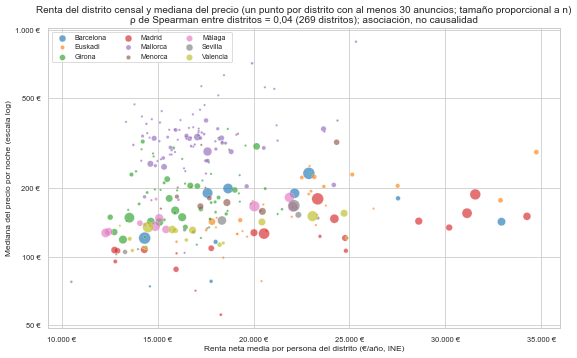

In [13]:
viz.fig_renta_precio_zonas(df, findings);

In [14]:
eco = RP["ecologico_global"]
lectura(f"**Lectura.** Con un punto por distrito (los {fmt.n0(eco['n_zonas'])} que tienen al menos "
        f"{config.MIN_N_GRUPO} anuncios con precio), la correlación entre la renta y la mediana del precio es "
        f"{fmt.n3(eco['rho'])} (p = {fmt.n3(eco['p'])}). La figura explica por qué: cada ciudad forma su propia "
        "nube, a distinta altura. Las regiones con precios altos tienen rentas moderadas y las ciudades con más renta "
        "no son las más caras, así que al mezclarlas la relación se diluye. Hay que mirar dentro de cada ciudad.")

**Lectura.** Con un punto por distrito (los 269 que tienen al menos 30 anuncios con precio), la correlación entre la renta y la mediana del precio es 0,040 (p = 0,515). La figura explica por qué: cada ciudad forma su propia nube, a distinta altura. Las regiones con precios altos tienen rentas moderadas y las ciudades con más renta no son las más caras, así que al mezclarlas la relación se diluye. Hay que mirar dentro de cada ciudad.

### Por ciudad

La misma ρ, ciudad a ciudad, con el IC remuestreando distritos. Son nueve contrastes a la vez, así que los
p-valores se corrigen con Holm. La última columna es la correlación entre distritos (un punto por distrito).

In [15]:
tabla_rp = pd.DataFrame([{
    "ciudad": c["ciudad"], "n": c["distrito"]["n"], "distritos": c["distrito"]["cluster_zona"]["n_clusters"],
    "rho": round(c["distrito"]["rho"], 3), "ic_inf": round(c["distrito"]["cluster_zona"]["ic_inf"], 3),
    "ic_sup": round(c["distrito"]["cluster_zona"]["ic_sup"], 3), "p_boot": round(c["distrito"]["cluster_zona"]["p_boot"], 3),
    "p_holm": round(c["distrito"]["holm"]["p_holm"], 3),
    "rho_entre_distritos": round(c["ecologico"]["rho"], 2) if c["ecologico"]["evaluable"] else np.nan,
} for c in RP["por_ciudad"] if c["distrito"]["evaluable"]])
tabla_rp

,ciudad,n,distritos,rho,ic_inf,ic_sup,p_boot,p_holm,rho_entre_distritos
0,Euskadi,5520,284,0.286,0.187,0.367,0.002,0.018,0.64
1,Málaga,8523,14,0.235,0.071,0.302,0.008,0.048,0.72
2,Girona,14968,246,0.209,0.087,0.306,0.004,0.032,0.21
3,Sevilla,7723,11,0.175,0.041,0.315,0.006,0.042,0.95
4,Madrid,18785,21,0.173,0.018,0.325,0.034,0.170,0.73
5,Barcelona,12610,11,0.152,-0.085,0.248,0.276,0.827,0.45
6,Menorca,2948,17,0.148,-0.082,0.341,0.316,0.827,0.42
7,Valencia,7196,19,0.126,-0.008,0.203,0.060,0.240,0.36
8,Mallorca,10984,115,0.030,-0.052,0.109,0.472,0.827,0.16


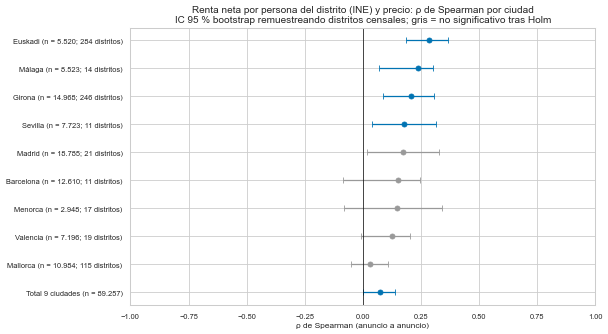

In [16]:
viz.fig_spearman_ciudad(findings);

In [17]:
sig = tabla_rp[tabla_rp["p_holm"] < config.ALFA]["ciudad"].tolist()
lectura(f"**Lectura.** Dentro de cada ciudad la correlación es positiva en {(tabla_rp['rho'] > 0).sum()} de las {len(tabla_rp)} zonas, de "
        f"{fmt.n3(tabla_rp['rho'].min())} en {tabla_rp.loc[tabla_rp['rho'].idxmin(), 'ciudad']} a "
        f"{fmt.n3(tabla_rp['rho'].max())} en {tabla_rp.loc[tabla_rp['rho'].idxmax(), 'ciudad']}. Tras Holm son "
        f"significativas {len(sig)}: {', '.join(sig) or 'ninguna'}. En las ciudades con una o dos decenas de distritos "
        "los intervalos son anchos, porque la renta solo toma esos pocos valores distintos. La correlación entre "
        "distritos puede ser alta en ellas (cada distrito resume cientos de anuncios), pero con tan pocos puntos es "
        "poco precisa y no permite extrapolar al anuncio individual.")

**Lectura.** Dentro de cada ciudad la correlación es positiva en 9 de las 9 zonas, de 0,030 en Mallorca a 0,286 en Euskadi. Tras Holm son significativas 4: Euskadi, Málaga, Girona, Sevilla. En las ciudades con una o dos decenas de distritos los intervalos son anchos, porque la renta solo toma esos pocos valores distintos. La correlación entre distritos puede ser alta en ellas (cada distrito resume cientos de anuncios), pero con tan pocos puntos es poco precisa y no permite extrapolar al anuncio individual.

In [18]:
sens = pd.DataFrame({k: {"n": v["n"], "rho": round(v["rho"], 3), "ic_inf": round(v["cluster_zona"]["ic_inf"], 3),
                         "ic_sup": round(v["cluster_zona"]["ic_sup"], 3)} for k, v in RP["sensibilidades"].items()}).T
sens

,n,rho,ic_inf,ic_sup
sin_estancias_30,80241.0,0.118,0.031,0.208
sin_outliers,85501.0,0.092,0.020,0.152
un_anuncio_por_anfitrion,32509.0,0.103,0.035,0.180
solo_urbanas,54837.0,0.168,0.098,0.228


In [19]:
lectura(f"**Lectura de las sensibilidades.** El signo de la ρ global "
        f"{'se mantiene' if RP['sensibilidades_mismo_signo'] else 'no se mantiene'} sin estancias largas, sin "
        "atípicos, con un anuncio por anfitrión y solo en las ciudades urbanas. En las urbanas la correlación es algo "
        f"mayor (ρ = {fmt.n3(RP['sensibilidades']['solo_urbanas']['rho'])}), lo que encaja con que las regiones "
        "diluyan la relación.")

**Lectura de las sensibilidades.** El signo de la ρ global se mantiene sin estancias largas, sin atípicos, con un anuncio por anfitrión y solo en las ciudades urbanas. En las urbanas la correlación es algo mayor (ρ = 0,168), lo que encaja con que las regiones diluyan la relación.

## 5. Regresión OLS sobre ln(precio)

La correlación no controla nada. La regresión estima la asociación de cada variable con ln(precio) **manteniendo
constantes las demás**:

- Efectos fijos de ciudad (cada ciudad tiene su propio nivel; la referencia es Madrid). Así la renta se compara
  dentro de cada ciudad y no entre ciudades.
- Tipo de habitación, capacidad, dormitorios, baños, baño compartido, amenities, superhost, anfitrión con varios
  anuncios, estancia mínima larga, reseñas, licencia y mes de la cotización (temporada).
- Variables del INE del distrito: ln(renta neta por persona), Gini, edad media y % de hogares unipersonales.

H0 para cada coeficiente: β = 0. Errores agrupados por anfitrión; los términos del INE se contrastan además
agrupando por distrito. Como la renta entra en logaritmo, su coeficiente es una elasticidad: se traduce al cambio
del precio asociado a una renta un 10 % mayor. Se reajusta aquí para tener los residuos.

In [20]:
ajuste = est.ajustar_ols(df)
residuos = ajuste.pop("_residuos")
ajustados = ajuste.pop("_ajustados")
ajuste.pop("_indices")
coefs = pd.DataFrame([c for c in ajuste["coeficientes"] if not c["es_mes"]])
coefs[["nombre", "pct", "ic_inf_pct", "ic_sup_pct", "p_cluster", "significativo_holm"]].round(3)

,nombre,pct,ic_inf_pct,ic_sup_pct,p_cluster,significativo_holm
0,Tipo: Habitación compartida,-65.731,-70.343,-60.403,0.000,True
1,Tipo: Habitación de hotel,5.642,-8.044,21.364,0.438,False
2,Tipo: Habitación privada,-25.244,-28.563,-21.772,0.000,True
3,Licencia: Con nº de registro,6.268,3.779,8.817,0.000,True
4,Licencia: Exenta,-13.164,-17.314,-8.807,0.000,True
5,Licencia: Otro / en proceso,19.155,8.349,31.038,0.000,True
6,Ciudad: Barcelona,30.841,24.732,37.249,0.000,True
7,Ciudad: Euskadi,9.632,4.651,14.850,0.000,True
8,Ciudad: Girona,-10.297,-13.713,-6.746,0.000,True
9,Ciudad: Mallorca,39.491,26.853,53.389,0.000,True


R² ajustado (celda) = 0,6086; pipeline = 0,6086; n = 89.182


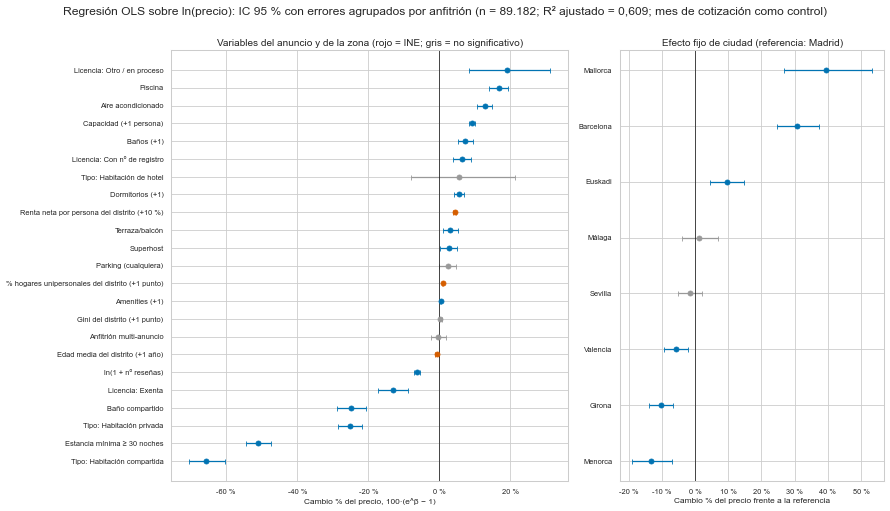

In [21]:
print(f"R² ajustado (celda) = {fmt.n4(ajuste['r2_ajustado'])}; pipeline = {fmt.n4(OLS['r2_ajustado'])}; n = {fmt.n0(ajuste['n_efectivo'])}")
viz.fig_ols_coeficientes(findings);

In [22]:
cr = OLS["coef_renta"]
lectura(f"**Lectura.** El modelo explica una parte importante de la variación del logaritmo del precio "
        f"(R² ajustado = {fmt.n3(OLS['r2_ajustado'])}). Las asociaciones más grandes son de las características del "
        f"alojamiento: cada persona más de capacidad {fmt.signo_pct(OLS['coef_accommodates']['pct'])}, habitación "
        f"privada frente a entero {fmt.signo_pct(OLS['coef_privada']['pct'])}, estancia mínima larga "
        f"{fmt.signo_pct(OLS['coef_larga_estancia']['pct'])} por noche. Ser superhost "
        f"({fmt.signo_pct(OLS['coef_superhost']['pct'])}) o tener varios anuncios "
        f"({fmt.signo_pct(OLS['coef_multianuncio']['pct'])}) apenas importa. Con todo eso constante, una renta del "
        f"distrito un 10 % mayor se asocia con un precio {fmt.signo_pct(cr['pct_por_10pct_renta'])} mayor (IC "
        f"agrupando por distrito {fmt.signo_pct(cr['ic_inf_10pct_distrito'])} a "
        f"{fmt.signo_pct(cr['ic_sup_10pct_distrito'])}). Es una asociación condicional dentro de cada ciudad; la renta "
        "puede estar recogiendo otras cualidades de la zona que no se miden.")

**Lectura.** El modelo explica una parte importante de la variación del logaritmo del precio (R² ajustado = 0,609). Las asociaciones más grandes son de las características del alojamiento: cada persona más de capacidad +9,1 %, habitación privada frente a entero -25,2 %, estancia mínima larga -51,1 % por noche. Ser superhost (+2,6 %) o tener varios anuncios (-0,3 %) apenas importa. Con todo eso constante, una renta del distrito un 10 % mayor se asocia con un precio +4,3 % mayor (IC agrupando por distrito +3,4 % a +5,2 %). Es una asociación condicional dentro de cada ciudad; la renta puede estar recogiendo otras cualidades de la zona que no se miden.

### ¿Cuánto aporta la renta?

Se compara el R² ajustado del modelo con y sin las cuatro variables del INE, con exactamente las mismas filas.

In [23]:
pd.DataFrame({"R² ajustado": {"con INE": OLS["r2_ajustado"], "sin INE": OLS["sin_ine"]["r2_ajustado"],
                              "solo ciudad, tipo, licencia e INE": OLS["solo_ciudad_tipo_licencia_ine"]["r2_ajustado"]}}).round(4)

,R² ajustado
con INE,0.6086
sin INE,0.5877
"solo ciudad, tipo, licencia e INE",0.2950


In [24]:
urb = OLS["sensibilidades"]["solo_urbanas_con_distancia"]
lectura(f"**Lectura.** Las variables del INE añaden {fmt.n1(OLS['delta_r2_ajustado_ine_pp'])} puntos de R² ajustado. "
        "La relación es clara y estable, pero **explica poco**: el precio depende sobre todo del alojamiento y de la "
        "ciudad. En las ciudades urbanas, al añadir la distancia al centro, la asociación de la renta baja a "
        f"{fmt.signo_pct(urb['renta']['pct_por_10pct_renta'])} por cada 10 % de renta y cada km se asocia con "
        f"{fmt.signo_pct(urb['distancia']['pct'])}: parte de la asociación de la renta puede reflejar la centralidad de la zona.")

**Lectura.** Las variables del INE añaden 2,1 puntos de R² ajustado. La relación es clara y estable, pero **explica poco**: el precio depende sobre todo del alojamiento y de la ciudad. En las ciudades urbanas, al añadir la distancia al centro, la asociación de la renta baja a +3,2 % por cada 10 % de renta y cada km se asocia con -3,2 %: parte de la asociación de la renta puede reflejar la centralidad de la zona.

### Diagnóstico del modelo

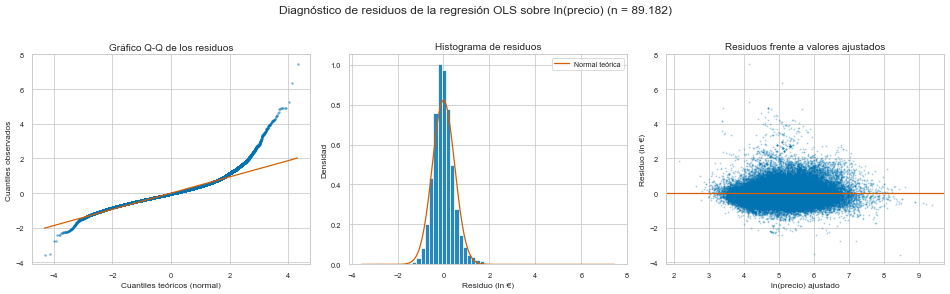

In [25]:
viz.fig_ols_residuos({"residuos": residuos, "ajustados": ajustados});

In [26]:
dg = OLS["diagnostico"]
vif = pd.DataFrame(OLS["vif"])[["nombre", "vif"]].round(2)
lectura(f"**Lectura.** Breusch-Pagan detecta heterocedasticidad ({fmt.p_texto(dg['breusch_pagan_p'])}) y Jarque-Bera "
        f"rechaza la normalidad de los residuos (asimetría {fmt.n2(dg['asimetria_residuos'])}, curtosis "
        f"{fmt.n1(dg['curtosis_residuos'])}): el Q-Q muestra colas pesadas, sobre todo la de precios más altos de lo "
        "esperado. Por eso los errores son robustos y agrupados; con este tamaño muestral la inferencia sobre los "
        f"coeficientes sigue siendo aproximadamente válida. El VIF máximo es {fmt.n2(vif['vif'].max())} "
        f"({vif.loc[vif['vif'].idxmax(), 'nombre']}), sin problemas graves de colinealidad, y con la matriz completa el "
        f"GVIF ajustado máximo es {fmt.n2(OLS['gvif_max']['gvif_ajustado'])}.")

**Lectura.** Breusch-Pagan detecta heterocedasticidad (p < 0,001) y Jarque-Bera rechaza la normalidad de los residuos (asimetría 1,33, curtosis 10,7): el Q-Q muestra colas pesadas, sobre todo la de precios más altos de lo esperado. Por eso los errores son robustos y agrupados; con este tamaño muestral la inferencia sobre los coeficientes sigue siendo aproximadamente válida. El VIF máximo es 3,83 (Capacidad (+1 persona)), sin problemas graves de colinealidad, y con la matriz completa el GVIF ajustado máximo es 2,03.

In [27]:
vif.head(8)

,nombre,vif
0,Capacidad (+1 persona),3.83
1,Dormitorios (+1),3.78
2,Gini del distrito (+1 punto),2.86
3,Baños (+1),2.26
4,ln(renta neta por persona del distrito),2.14
5,% hogares unipersonales del distrito (+1 punto),2.13
6,Tipo: Habitación privada,2.08
7,Baño compartido,1.90


### Sensibilidades del modelo

In [28]:
pd.DataFrame({k: {"n": v["n_efectivo"], "R² ajustado": round(v["r2_ajustado"], 3),
                  "renta +10 % (%)": round(v["renta"]["pct_por_10pct_renta"], 2),
                  "mismo signo en coef. clave": v["todos_mismo_signo"]}
              for k, v in OLS["sensibilidades"].items()}).T

,n,R² ajustado,renta +10 % (%),mismo signo en coef. clave
sin_outliers,85427,0.593,4.27,True
sin_estancias_30,80173,0.572,4.49,False
un_anuncio_por_anfitrion,32484,0.611,4.53,True
solo_urbanas_con_distancia,54798,0.605,3.18,False
sin_mes,89182,0.59,4.05,False


In [29]:
lectura(f"**Lectura.** El coeficiente de la renta "
        f"{'conserva el signo en todas las variantes' if OLS['sensibilidades_renta_mismo_signo'] else 'cambia de signo en alguna variante'}: "
        "sin atípicos, sin estancias mínimas largas, con un anuncio por anfitrión, solo en ciudades urbanas y sin el "
        "control del mes. La conclusión no depende de esas decisiones de limpieza.")

**Lectura.** El coeficiente de la renta conserva el signo en todas las variantes: sin atípicos, sin estancias mínimas largas, con un anuncio por anfitrión, solo en ciudades urbanas y sin el control del mes. La conclusión no depende de esas decisiones de limpieza.

## 6. Modelo de machine learning complementario

Un HistGradientBoosting puede captar relaciones no lineales e interacciones. Para compararlo de forma justa:

- Validación cruzada **agrupada por anfitrión** (`GroupKFold`, cinco particiones): ningún anfitrión está a la vez
  en entrenamiento y en prueba. Una partición aleatoria por anuncio dejaría que el modelo «reconociera» al
  anfitrión y daría una cifra optimista.
- La imputación y la agrupación de categorías raras se aprenden dentro del pipeline, solo con el entrenamiento.
- Comparación homogénea con la regresión lineal: mismas filas, mismas particiones y mismas variables.

In [30]:
comp = ML["comparacion_misma_muestra"]
pd.DataFrame({"R² medio (GroupKFold)": {
    "Línea base (mediana)": ML["cv_base"]["r2_media"], "Lineal, variables del OLS": comp["lineal_vars_ols"]["r2_media"],
    "HGB, variables del OLS": comp["hgb_vars_ols"]["r2_media"], "HGB, todas las variables": ML["cv"]["r2_media"],
    "HGB, sin variables del INE": ML["cv_sin_ine"]["r2_media"], "HGB, partición aleatoria (optimista)": ML["aleatorio"]["r2"],
}}).round(3)

,R² medio (GroupKFold)
Línea base (mediana),-0.008
"Lineal, variables del OLS",0.602
"HGB, variables del OLS",0.661
"HGB, todas las variables",0.713
"HGB, sin variables del INE",0.698
"HGB, partición aleatoria (optimista)",0.769


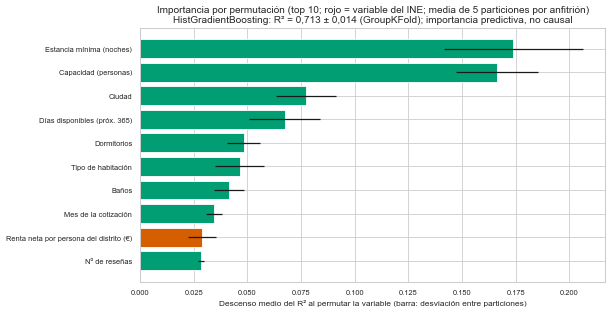

In [31]:
viz.fig_importancia_variables(findings);

In [32]:
lectura(f"**Lectura.** Con las mismas filas, particiones y variables, el HistGradientBoosting "
        f"(R² = {fmt.n3(comp['hgb_vars_ols']['r2_media'])}) mejora a la regresión lineal "
        f"({fmt.n3(comp['lineal_vars_ols']['r2_media'])}), lo que indica relaciones no lineales. Con todas sus variables "
        f"llega a {fmt.n3(ML['cv']['r2_media'])} ± {fmt.n3(ML['cv']['r2_std'])}; la partición aleatoria daría "
        f"{fmt.n3(ML['aleatorio']['r2'])}, una cifra inflada. Quitar las variables del INE baja el R² a "
        f"{fmt.n3(ML['cv_sin_ine']['r2_media'])}: la zona aporta {fmt.n3(ML['aporte_r2_ine'])} de R². En la importancia "
        f"por permutación la primera variable del INE aparece en el puesto {ML['rango_ine_en_importancia']}, por detrás "
        "de la capacidad, la estancia mínima o la ciudad. La importancia es predictiva, no causal.")

**Lectura.** Con las mismas filas, particiones y variables, el HistGradientBoosting (R² = 0,661) mejora a la regresión lineal (0,602), lo que indica relaciones no lineales. Con todas sus variables llega a 0,713 ± 0,014; la partición aleatoria daría 0,769, una cifra inflada. Quitar las variables del INE baja el R² a 0,698: la zona aporta 0,016 de R². En la importancia por permutación la primera variable del INE aparece en el puesto 9, por detrás de la capacidad, la estancia mínima o la ciudad. La importancia es predictiva, no causal.

## 7. Multiplicidad

In [33]:
pd.Series(E["multiplicidad"], name="número").to_frame()

,número
n_contrastes_principales,6
n_principales_p_menor_0001,6
n_pares_posthoc,42
n_coeficientes_ols,43
n_significativos_ols,33
n_significativos_ols_holm,29
n_rho_ciudad,9
n_hipotesis_total,100


Las comparaciones post-hoc se corrigen con Bonferroni y los coeficientes del OLS y las correlaciones por ciudad
con Holm. Las conclusiones se apoyan en los resultados que sobreviven a la corrección y en los tamaños de efecto.

## Conclusiones

1. **Ciudad y tipo de habitación** se asocian claramente con el precio; el tipo de habitación separa más.
2. **La renta de la zona** se relaciona positivamente con el precio **dentro de cada ciudad**, de forma estable en
   todas las sensibilidades, pero con un efecto modesto. Mezclando ciudades la relación casi desaparece.
3. En la regresión con controles, la renta añade poco a la explicación del precio, y en el modelo predictivo
   también. **La renta explica poco del precio**: pesan mucho más el tamaño y el tipo del alojamiento, la estancia
   mínima y la ciudad.
4. Todo son asociaciones observacionales, con datos scrapeados en un único momento y una renta de 2024 frente a
   anuncios de 2026.